In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [34]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tawfikelmetwally/wine-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'wine-dataset' dataset.
Path to dataset files: /kaggle/input/wine-dataset


In [35]:
data=pd.read_csv('/kaggle/input/wine-dataset/Wine dataset.csv')

In [36]:
df = pd.DataFrame(data)

#**basic** **info**

In [37]:
print("First 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

First 5 Rows:
   class  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color intensity   Hue  OD280/OD315 of diluted wines  Proline   
0             5.64  1.04                          3.92      1065  
1         

# **Question 1 :** How many wines belong to each class?

In [38]:
class_count = df['class'].value_counts().sort_index()

print(class_count)

class
1    59
2    71
3    48
Name: count, dtype: int64


**QUES2:** What are the mean, median, minimum and maximum alcohol values?

In [46]:
alcohol = np.array(df['Alcohol'])

print("Mean:", np.mean(alcohol))
print("Median:", np.median(alcohol))
print("Minimum:", np.min(alcohol))
print("Maximum:", np.max(alcohol))

Mean: 13.00061797752809
Median: 13.05
Minimum: 11.03
Maximum: 14.83


**ques 3**  Which class has the highest average alcohol and magnesium values?

In [40]:
result = df.groupby('class')[['Alcohol', 'Magnesium']].mean()

print(result)

         Alcohol   Magnesium
class                       
1      13.744746  106.338983
2      12.278732   94.549296
3      13.153750   99.312500


**ques4**  Which records have the highest color intensity?

In [41]:
print(df.sort_values(
    by='Color intensity',
    ascending=False
).head(5))

     class  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
158      3    14.34        1.68  2.70               25.0         98   
159      3    13.48        1.67  2.64               22.5         89   
151      3    12.79        2.67  2.48               22.0        112   
166      3    13.45        3.70  2.60               23.0        111   
153      3    13.23        3.30  2.28               18.5         98   

     Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
158           2.80        1.31                  0.53             2.70   
159           2.60        1.10                  0.52             2.29   
151           1.48        1.36                  0.24             1.26   
166           1.70        0.92                  0.43             1.46   
153           1.80        0.83                  0.61             1.87   

     Color intensity   Hue  OD280/OD315 of diluted wines  Proline   
158            13.00  0.57                          1.96       66

**ques5** Check for missing values and duplicates

In [42]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
class                           0
Alcohol                         0
Malic acid                      0
Ash                             0
Alcalinity of ash               0
Magnesium                       0
Total phenols                   0
Flavanoids                      0
Nonflavanoid phenols            0
Proanthocyanins                 0
Color intensity                 0
Hue                             0
OD280/OD315 of diluted wines    0
Proline                         0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0


**ques6** Compare the average values of alcohol, malic acid and color intensity by class.

In [43]:
comparison = df.groupby('class')[
    ['Alcohol', 'Malic acid', 'Color intensity']
].mean()

print(comparison)

         Alcohol  Malic acid  Color intensity
class                                        
1      13.744746    2.010678         5.528305
2      12.278732    1.932676         3.086620
3      13.153750    3.333750         7.396250


# . **Create Class Count Bar Chart**

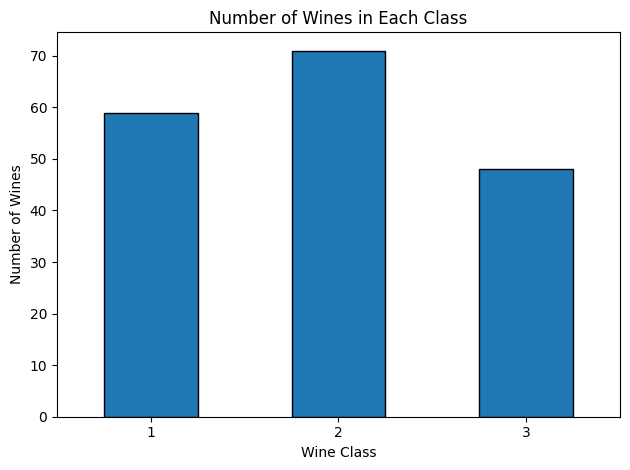

In [44]:
class_count.plot(kind='bar', edgecolor='black')

plt.title("Number of Wines in Each Class")
plt.xlabel("Wine Class")
plt.ylabel("Number of Wines")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# **create alc histogram**

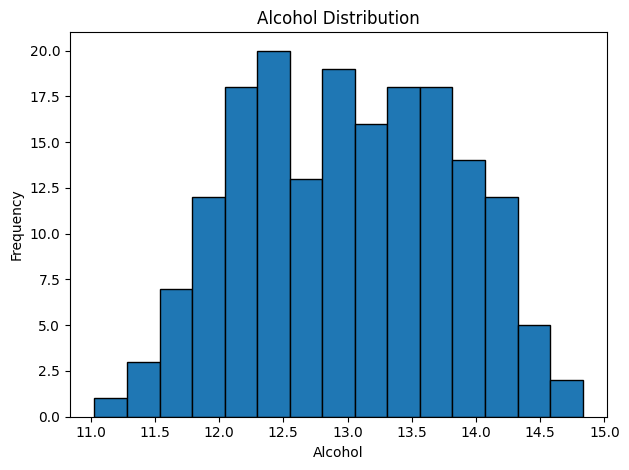

In [45]:
plt.hist(alcohol, bins=15, edgecolor='black')

plt.title("Alcohol Distribution")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# ***Three Observations***
1. Class 2 contains the highest number of wines (71), while Class 3 contains the lowest number (48).
2. Class 1 has the highest average alcohol and magnesium values.
3. Class 3 has the highest average malic acid and color intensity values.